# PSV PROJECT

This is the first notebook which will be using EfficientNet pre-trained model. The data of this project is on the folder raw- images and the tabular data is on pandas multilabel-dataset.csv
First we need to create virtual enviroment, in this case is called  'nahiavenv' 
Afterwards, we need to download all the needed libraries. Such as :tensorflow, pandas, scikit-learn, pillow, matplotlib, numpy

In [1]:
import os
import pandas as pd
import tensorflow as tf
import numpy as np


BASE_DIR   = r"c:\Users\Nahia\OneDrive - Office 365 Fontys\ICT\SEMESTER 3\PSV project"
DATA_DIR   = os.path.join(BASE_DIR, "data")
IMAGES_DIR = os.path.join(BASE_DIR, "raw_images")
MODELS_DIR = os.path.join(BASE_DIR, "models")
print(BASE_DIR)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input


c:\Users\Nahia\OneDrive - Office 365 Fontys\ICT\SEMESTER 3\PSV project


### Loading and Preparing the Dataset

The first step in the pipeline is loading and preparing the dataset for training. The dataset consists of images collected from Instagram posts and manually labelled into predefined categories. The image paths and corresponding labels are stored in a CSV file.

In [2]:
df = pd.read_csv(os.path.join(DATA_DIR, "multilabel_dataset.csv"))
print("Rows loaded:", len(df))
print("Columns:", df.columns.tolist())
print("Sample image_path:", df["image_path"].iloc[0])

Rows loaded: 479
Columns: ['image_path', 'shortcode', 'likes', 'timestamp', 'caption', 'comment_count', 'category', 'PLAYER', 'ACTION', 'GRAPHIC', 'CROWD', 'CELEBRATION']
Sample image_path: raw_images/DMhd4aiMXhj_0.jpg


In [3]:
df["image_path"] = df["image_path"].apply(
    lambda x: os.path.join(IMAGES_DIR, os.path.basename(x))
)

print(df["image_path"].iloc[0]) 
print("Files found:", df["image_path"].apply(os.path.exists).sum())

c:\Users\Nahia\OneDrive - Office 365 Fontys\ICT\SEMESTER 3\PSV project\raw_images\DMhd4aiMXhj_0.jpg
Files found: 479


### Multi-Label Encoding
Each image can belong to multiple categories simultaneously. The five label columns
(`crowd`, `celebration`, `graphic`, `player`, `action`) are already binary (0/1),
so no further encoding is needed.

In [4]:
LABEL_COLS = ["CROWD", "CELEBRATION", "GRAPHIC", "PLAYER", "ACTION"]
NUM_CLASSES = len(LABEL_COLS)

# Check existing columns
assert all(col in df.columns for col in LABEL_COLS), "Faltan columnas en el CSV"

# Convert to float32
df["label_vector"] = df[LABEL_COLS].values.tolist()

### Train/Validation/Test
Split the dataset into training (68%), validation (17%), and test (15%) sets.
Stratification is skipped since labels are multi-label vectors.

In [5]:
train_val_df, test_df = train_test_split(df, test_size=0.15, random_state=42)
train_df, val_df      = train_test_split(train_val_df, test_size=0.2, random_state=42)

### Data Pipeline
Build efficient `tf.data` pipelines for each split. Images are read from disk, decoded,
resized to 224×224, and preprocessed for EfficientNet.

In [6]:
IMG_SIZE   = 224
BATCH_SIZE = 16

def process_image(image_path, label):
    try:
        image = tf.io.read_file(image_path)
        image = tf.image.decode_image(image, channels=3, expand_animations=False)
        image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
        image = preprocess_input(image)
    except Exception:
        image = tf.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32)
    return image, label
def make_dataset(dataframe, shuffle=False):
    paths  = dataframe["image_path"].values
    labels = np.stack(dataframe[LABEL_COLS].values).astype("float32")  # shape (N, 5)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(process_image, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(1000)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds
train_ds = make_dataset(train_df, shuffle=True)
val_ds   = make_dataset(val_df)
test_ds  = make_dataset(test_df)

### Data Augmentation
Apply random horizontal flips, rotations, and zoom during training to improve
generalization and reduce overfitting.

In [7]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

### Model 
Transfer learning with EfficientNetB0 pretrained on ImageNet. The base model is frozen
and a custom classification head is added. The output layer uses `sigmoid` activation —
one independent probability per label.

In [8]:
base_model = MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model.trainable = False

model = models.Sequential([
    data_augmentation,
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="sigmoid")  # ← sigmoid, no softmax
])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


### Compilation
Compile with `binary_crossentropy` loss, which treats each label as an independent
binary classification problem. AUC and binary accuracy are tracked as metrics.

In [9]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",            # ← una loss independiente por label
    metrics=[
        tf.keras.metrics.AUC(name="auc", multi_label=True),
        tf.keras.metrics.BinaryAccuracy(name="binary_accuracy", threshold=0.5)
    ]
)

### Training 
Train for up to 30 epochs with early stopping monitoring `val_auc`.
Best weights are automatically restored if validation performance degrades

In [10]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(
    monitor="val_auc",
    patience=5,
    restore_best_weights=True,
    mode="max"                             # ← AUC se maximiza
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping]
)

Epoch 1/30
21/21 ━━━━━━━━━━━━━━━━━━━━ 16s 449ms/step - auc: 0.5494 - binary_accuracy: 0.7692 - loss: 0.5605 - val_auc: 0.7712 - val_binary_accuracy: 0.8049 - val_loss: 0.4031
Epoch 2/30
21/21 ━━━━━━━━━━━━━━━━━━━━ 11s 400ms/step - auc: 0.7196 - binary_accuracy: 0.8037 - loss: 0.4449 - val_auc: 0.8509 - val_binary_accuracy: 0.8512 - val_loss: 0.3418
Epoch 3/30
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 382ms/step - auc: 0.7804 - binary_accuracy: 0.8178 - loss: 0.4030 - val_auc: 0.8827 - val_binary_accuracy: 0.8683 - val_loss: 0.3186
Epoch 4/30
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 384ms/step - auc: 0.8297 - binary_accuracy: 0.8443 - loss: 0.3581 - val_auc: 0.8974 - val_binary_accuracy: 0.8780 - val_loss: 0.3002
Epoch 5/30
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 394ms/step - auc: 0.8495 - binary_accuracy: 0.8597 - loss: 0.3366 - val_auc: 0.9020 - val_binary_accuracy: 0.8780 - val_loss: 0.2916
Epoch 6/30
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 385ms/step - auc: 0.8817 - binary_accuracy: 0.8714 - loss: 0.3092 - val_auc: 0.9096

### Prediction 
Run inference on the test set. Raw sigmoid outputs (0–1) are thresholded at 0.5
to produce binary predictions for each label.

In [11]:
THRESHOLD = 0.5

preds = model.predict(test_ds)             # shape: (N, 5)
binary_preds = (preds >= THRESHOLD).astype(int)

# See the result as a DataFrame for better readability
results_df = pd.DataFrame(binary_preds, columns=LABEL_COLS)
print(results_df.head())

5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 434ms/step
   CROWD  CELEBRATION  GRAPHIC  PLAYER  ACTION
0      0            0        1       1       0
1      0            0        0       1       0
2      0            0        0       1       0
3      0            0        0       1       0
4      0            0        1       1       0


5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 260ms/step


c:\Users\Nahia\OneDrive - Office 365 Fontys\ICT\SEMESTER 3\PSV project\nahiavenv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Nahia\OneDrive - Office 365 Fontys\ICT\SEMESTER 3\PSV project\nahiavenv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Nahia\OneDrive - Office 365 Fontys\ICT\SEMESTER 3\PSV project\nahiavenv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. U

              precision    recall  f1-score   support

       CROWD       0.67      0.25      0.36         8
 CELEBRATION       0.00      0.00      0.00         5
     GRAPHIC       0.79      0.77      0.78        30
      PLAYER       0.86      0.98      0.92        58
      ACTION       0.80      0.40      0.53        10

   micro avg       0.83      0.77      0.80       111
   macro avg       0.62      0.48      0.52       111
weighted avg       0.79      0.77      0.77       111
 samples avg       0.82      0.77      0.77       111



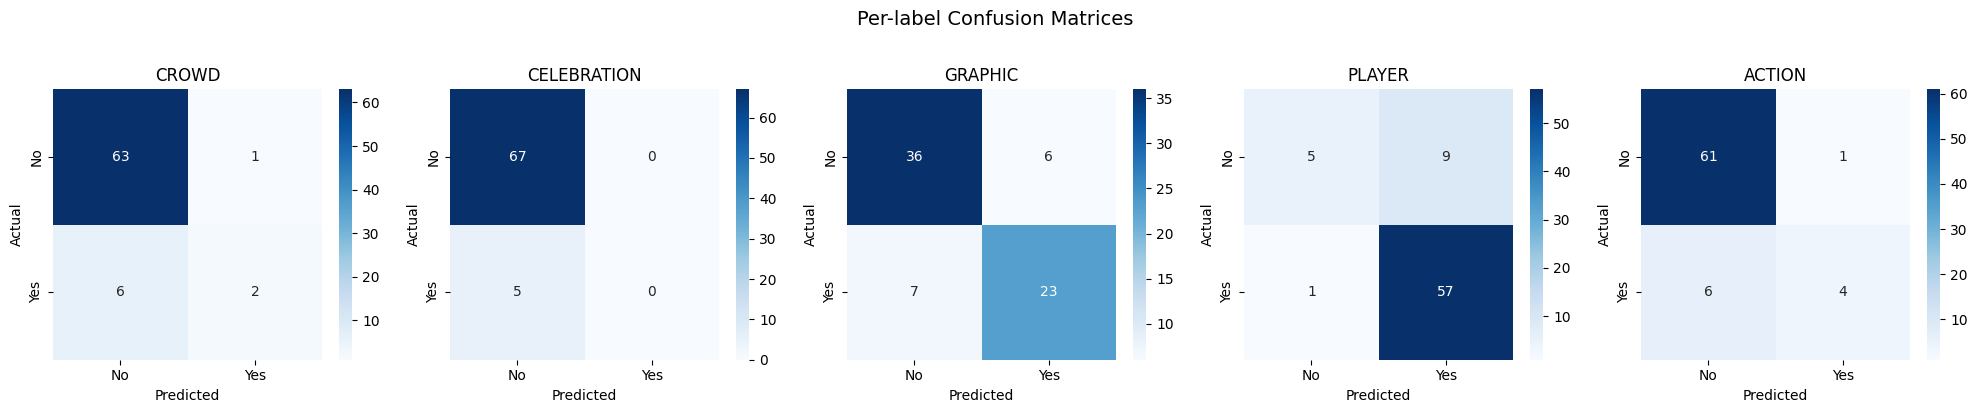

In [12]:
## 📊 10. Evaluation — Confusion Matrix & Metrics
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report, confusion_matrix
)

THRESHOLD = 0.5

# ── Get predictions ──────────────────────────────────────────────────────────
y_pred_probs = model.predict(test_ds)                          # shape: (N, 5)
y_pred       = (y_pred_probs >= THRESHOLD).astype(int)

# Ground truth — extract labels from test_ds
y_true = np.concatenate([y for _, y in test_ds], axis=0)      # shape: (N, 5)

# ── Per-label Classification Report ─────────────────────────────────────────
print(classification_report(y_true, y_pred, target_names=LABEL_COLS))

# ── Per-label Confusion Matrix ───────────────────────────────────────────────
# In multi-label there's one confusion matrix per label
fig, axes = plt.subplots(1, len(LABEL_COLS), figsize=(20, 4))

for i, (label, ax) in enumerate(zip(LABEL_COLS, axes)):
    cm = confusion_matrix(y_true[:, i], y_pred[:, i])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"],
        ax=ax
    )
    ax.set_title(label)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Per-label Confusion Matrices", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
os.makedirs(MODELS_DIR, exist_ok=True)
model.save(os.path.join(MODELS_DIR, "mobilenet_multilabel.keras"))